# Classifier Guidance


In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib
from pathlib import Path

import torch
from torch import nn
import torch.nn.functional as F
import sklearn.metrics

from torch.utils.data import DataLoader
from utils import load_data

# define the device to use
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Device: {DEVICE}")

Device: cpu


## Data

In [2]:
# load data
data_train, train_loader, X_train, y_train = load_data(
    data_dir_path="../data", 
    type="train", 
    task="classification"
)

data_val, val_loader, X_val, y_val = load_data(
    data_dir_path="../data", 
    type="val", 
    task="classification"
)

print('\n',repr(data_train),'\n',repr(data_val))

# train data, task: classification
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020])
# val data, task: classification
 Tokens shape: torch.Size([2001, 129])
 Labels (shape): torch.Size([2001])

 ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129) 
 ProteinDataset(num_samples=2001, vocab_size=23, num_classes=3, max_length=129)


In [3]:
# check class balance per split before doing anything
from protgen.data import FAMILIES

counts = pd.DataFrame({"train": data_train.df.family.value_counts(),
                       "val": data_val.df.family.value_counts()}
                       ).loc[list(FAMILIES)]
print(counts)

        train  val
family            
AcyP     5340  667
HPr      5340  667
HU       5340  667


In [4]:
# prefix mask: which positions are a usable prefix x[:i+1]
# position 0 is <BOS> alone (no residue), positions past <EOS> are <PAD> -> both excluded
def prefix_mask(data):
    pos = torch.arange(data.max_length)
    lengths = torch.tensor(data.lengths)
    return (pos >= 1) & (pos <= lengths[:, None] + 1)   # (N, 129) bool, <EOS> included

mask_train, mask_val = prefix_mask(data_train), prefix_mask(data_val)

# the family label repeats at every position, so each prefix is its own training example
Y_train = y_train[:, None].expand(-1, data_train.max_length)
Y_val = y_val[:, None].expand(-1, data_val.max_length)

print(f"{int(mask_train.sum()):,} train prefixes from {len(data_train):,} sequences "
      f"({mask_train.sum() / len(data_train):.0f} each)")

1,537,909 train prefixes from 16,020 sequences (96 each)


## Encoding

In [ ]:
# load the frozen RNN encoder from the Phase-1 checkpoint
#
# needed from protgen.models.rnn:
#   RNNEncoder(**config)   forward(x) -> (next_token_logits, h_all)   h_all: (B, T, hidden)
#                          step(token, h) -> (logits, h_t, h_new)     one token on from state h
#   sample(model, n, ...)  the Phase-1 sampler, accepting a logit_fn hook
# needed in results/rnn.pt:
#   {"config": {...}, "state_dict": {...}}   so the architecture travels with the weights
from protgen.models.rnn import RNNEncoder

VOCAB_SIZE, NUM_CLASSES = data_train.vocab_size, len(data_train.fam_to_idx)

ckpt = torch.load("../results/rnn.pt", map_location=DEVICE)
encoder = RNNEncoder(**ckpt["config"]).to(DEVICE)
encoder.load_state_dict(ckpt["state_dict"])
encoder.eval().requires_grad_(False)

In [6]:
# use RNN to encode every sequence
@torch.no_grad()
def encode_all(X, bs=256):
    return torch.cat([encoder(X[i:i + bs].to(DEVICE))[1].cpu() for i in range(0, len(X), bs)])

H_train, H_val = encode_all(X_train), encode_all(X_val)
print(H_train.shape, H_val.shape)

torch.Size([16020, 129, 256]) torch.Size([2001, 129, 256])


## Classifier Training

In [ ]:
# train the classification head
# two heads, same data, different init: `head` guides generation, `eval_head` only scores samples
lr = 1e-3
batch_size = 256
epochs = 10

torch.manual_seed(0); head = nn.Linear(H_train.shape[-1], NUM_CLASSES).to(DEVICE)
torch.manual_seed(1); eval_head = nn.Linear(H_train.shape[-1], NUM_CLASSES).to(DEVICE)
opt = torch.optim.Adam([*head.parameters(), *eval_head.parameters()], lr=lr)

def masked_loss(model, H, Y, M):
    loss = F.cross_entropy(model(H).reshape(-1, NUM_CLASSES), Y.reshape(-1), reduction="none")
    return (loss * M.reshape(-1)).sum() / M.sum()

for epoch in range(epochs):
    perm = torch.randperm(len(H_train))
    for i in range(0, len(perm), batch_size):
        b = perm[i:i + batch_size]
        H, Y, M = H_train[b].to(DEVICE), Y_train[b].to(DEVICE), mask_train[b].to(DEVICE)
        loss = masked_loss(head, H, Y, M) + masked_loss(eval_head, H, Y, M)   # disjoint params
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        val = masked_loss(head, H_val.to(DEVICE), Y_val.to(DEVICE), mask_val.to(DEVICE))
    print(f"epoch {epoch}  train {loss.item():.3f}  val {val.item():.3f}")

In [8]:
# predict on validation
with torch.no_grad():
    pred = head(H_val.to(DEVICE)).argmax(-1).cpu()

correct = (pred == Y_val) & mask_val
acc_by_len = correct.sum(0) / mask_val.sum(0).clamp(min=1)     # accuracy per prefix length
print(f"overall val accuracy {correct.sum() / mask_val.sum():.3f}")
print(sklearn.metrics.classification_report(Y_val[mask_val], pred[mask_val], target_names=FAMILIES))

overall val accuracy 0.546
              precision    recall  f1-score   support

        AcyP       0.59      0.54      0.56     63729
         HPr       0.51      0.59      0.54     64886
          HU       0.55      0.51      0.53     62589

    accuracy                           0.55    191204
   macro avg       0.55      0.55      0.55    191204
weighted avg       0.55      0.55      0.55    191204



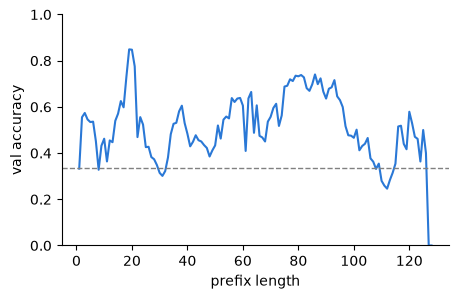

In [9]:
# accuracy vs. how much of the sequence the predictor has seen
ax = pd.Series(acc_by_len[1:].numpy(), index=range(1, data_train.max_length)).plot(
    figsize=(5, 3), color="#2a78d6", xlabel="prefix length", ylabel="val accuracy")
ax.axhline(1 / NUM_CLASSES, ls="--", c="grey", lw=1)   # chance
ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)

In [ ]:
# save both heads
torch.save({"head": head.state_dict(), "eval_head": eval_head.state_dict(),
            "hidden": H_train.shape[-1]}, "../results/classifier_head.pt")

## Guided generation

In [ ]:
# for guided generation we reuse the sampler from phase 1 and only swap the logits it samples from
from protgen.models.rnn import sample

TARGET = data_train.fam_to_idx["HU"]

def guidance(lam):
    """log p~ = log pθ(x_i|x<i) + λ log pφ(y|x≤i), scoring every candidate token."""
    @torch.no_grad()
    def logit_fn(logits, h, i):               # logits: (B, V), h: (layers, B, hidden) before x_i
        B, V = logits.shape
        cand = torch.arange(V, device=logits.device).repeat(B)            # (B*V,)
        _, h_next, _ = encoder.step(cand, h.repeat_interleave(V, dim=1))  # state after each cand
        logp_y = F.log_softmax(head(h_next), -1)[:, TARGET].view(B, V)
        return logits + lam * logp_y
    return logit_fn

for lam in [0.0, 1.0, 3.0, 10.0]:
    seqs = sample(encoder, n=100, logit_fn=guidance(lam))   # lam=0 == the unguided baseline
    pd.DataFrame({"sequence": seqs}).to_csv(
        f"../results/sequences/guided_lambda{lam:g}.csv", index=False)

In [ ]:
# predicted family of finished sequences, read off the state after <EOS>
# scored with eval_head, which did not guide the generation
@torch.no_grad()
def predict_family(seqs, model=None):
    X = torch.stack([data_train.encode(s) for s in seqs]).to(DEVICE)
    _, h = encoder(X)
    last = torch.tensor([len(s) + 1 for s in seqs], device=DEVICE)   # <BOS> + residues -> <EOS>
    return (model or eval_head)(h[torch.arange(len(seqs), device=DEVICE), last]).argmax(-1).cpu()

# sanity check on real proteins, should roughly recover the true families
real = data_val.df.sequence[:300]
print(pd.crosstab(data_val.df.family[:300], [FAMILIES[i] for i in predict_family(real)]))

In [ ]:
# target-family membership vs guidance strength
membership = {}
lambdas = [0.0, 1.0, 3.0, 10.0]
for lam in lambdas:
    seqs = pd.read_csv(f"../results/sequences/guided_lambda{lam:g}.csv").sequence
    membership[lam] = (predict_family(seqs) == TARGET).float().mean().item()

print(pd.Series(membership, name=f"fraction predicted {FAMILIES[TARGET]}"))